# 01 · ConvNeXt-Tiny: entrenamiento trinario frente a binario

**Pregunta:** ¿Cómo cambia la generalización en glaucoma al entrenar con tres clases (`Sano`, `Etapa inicial`, `Avanzado`) y proyectar a binario (`P(pos) = P(Inicial) + P(Avanzado)`), frente a entrenar directamente con dos clases (`Sano`, `Positivo`) desde un único dominio origen?

**Rol de cada dataset:** `Moondream Staged` es la **única cohorte local con etiquetas de severidad**. Por ello, ambos modelos se entrenan y calibran en `Moondream` (`504` entrenamiento / `107` validación), mientras **`ACRIMA` (`703`), `RIM-ONE DL` (`447`) y `EyePACS REAL` (`200`)** —que solo tienen etiquetas binarias— actúan como **cohortes externas completamente ciegas** para medir generalización fuera de dominio.

Referencia de selección de arquitectura: [Comprobacion_mejor_modelo.ipynb](../02_experimento_seleccion_datasets_y_modelos/Comprobacion_mejor_modelo.ipynb).

## 1. Configuración y particiones auditadas

Se carga `utilidades/dataset_auditado.csv` (`2.056` imágenes sin duplicados ni cruces geométricos). Solo `Moondream` se divide en `train` (`264/115/125`), `val` (`53/27/27`) y `test` (`49/21/25`).

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve
from torchvision import transforms as T

_root = Path.cwd().resolve()
if not (_root / "utilidades/utilidades.py").is_file() and (_root.parent / "utilidades/utilidades.py").is_file():
    _root = _root.parent
sys.path.insert(0, str(_root / "utilidades"))

import utilidades as u

ROOT = u.obtener_raiz()
SALIDAS = ROOT / "04_experimento_trinario_vs_binario/resultados"
SALIDAS.mkdir(parents=True, exist_ok=True)
MODELOS = ROOT / "modelos"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

EPOCHS = 20
BATCH_SIZE = 32
REENTRENAR = False

u.fijar_semilla(u.SEED)
df_datos, _ = u.cargar_dataset(ROOT)
cache_imgs = u.precargar_imagenes(df_datos["id"].tolist(), ROOT, max_lado=448)

train_df = df_datos[df_datos["split"] == "train"].reset_index(drop=True)
val_df = df_datos[df_datos["split"] == "val"].reset_index(drop=True)
eval_sets = {"Moondream · test": df_datos[df_datos["split"] == "test"].reset_index(drop=True)}
for fuente in ("ACRIMA", "RIM-ONE DL", "EyePACS REAL"):
    sub = df_datos[df_datos["coleccion"] == fuente].reset_index(drop=True)
    if len(sub):
        eval_sets[fuente] = sub

print(f"Dispositivo: {DEVICE} | Imágenes elegibles totales: {len(df_datos)}")
display(df_datos.groupby(["coleccion", "split", "clase"]).size().unstack(fill_value=0))

Dispositivo: cuda | Imágenes elegibles totales: 2056


clase                     advanced  early  glaucoma  normal
coleccion        split                                     
ACRIMA           externo         0      0       395     308
EyePACS REAL     externo         0      0       100     100
Moondream Staged test           25     21         0      49
                 train         125    115         0     264
                 val            27     27         0      53
RIM-ONE DL       externo         0      0       162     285

## 2. Entrenamiento controlado (`3c` vs. `2c`), curvas de convergencia y referencia (`3→3`)

Ambos brazos usan idéntica arquitectura (`ConvNeXt-Tiny`), partición (`504/107`), semilla (`42`), aumentos estándar (recorte y reescalado `0.8–1.0`, volteo horizontal, rotación `±15°` y fluctuación de color) y optimización (`AdamW`: `1` época de calentamiento `lr=1e-3` + `20` de ajuste fino `lr=1e-4 → 1e-6`, `wd=1e-4`). El mejor *checkpoint* y el umbral $\tau$ se seleccionan **solo en validación**.

Graficamos el historial de pérdidas (`train`/`val`) para comprobar en qué época empieza a sobreajustar el binario frente al trinario, y comparamos lado a lado la matriz `3×3` de referencia previa (`n=115`) frente a la partición auditada (`n=95`).

Modelo cargado: convnext_tiny_3c_estandar.pth (mejor época 10)


Modelo 3 clases · mejor ép. 10 · τ(Espec≥0.95)=0.81 (val=0.981) · τ(Youden)=0.81 (val=0.981)


Modelo cargado: convnext_tiny_2c_estandar.pth (mejor época 3)


Modelo 2 clases · mejor ép. 3 · τ(Espec≥0.95)=0.90 (val=0.962) · τ(Youden)=0.86 (val=0.925)


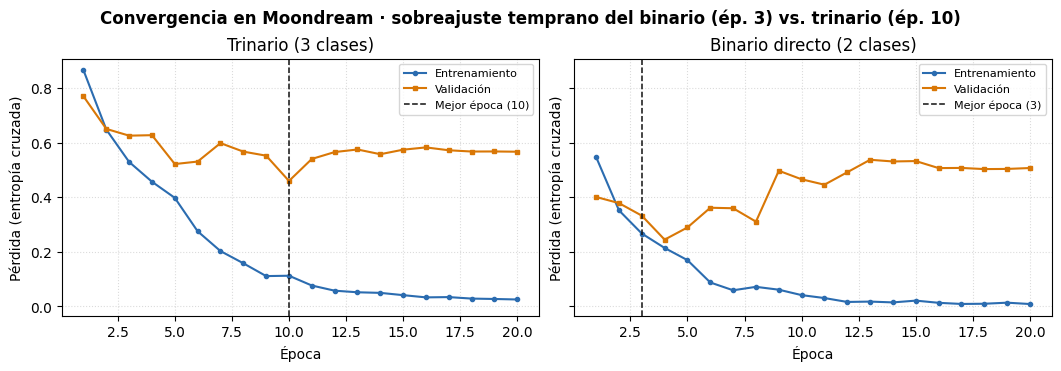

,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,recall inicial,recall avanzado,FN inicial,FN avanzado,errores sano ↔ avanzado
"Referencia previa (n=115, ép. 8)",115,0.722,0.774,0.804,0.932,0.068,0.196,0.519,0.69,6,5,7
"ConvNeXt 3c auditado (n=95, ép. 10)",95,0.731,0.789,0.935,0.898,0.102,0.065,0.476,0.84,3,0,3


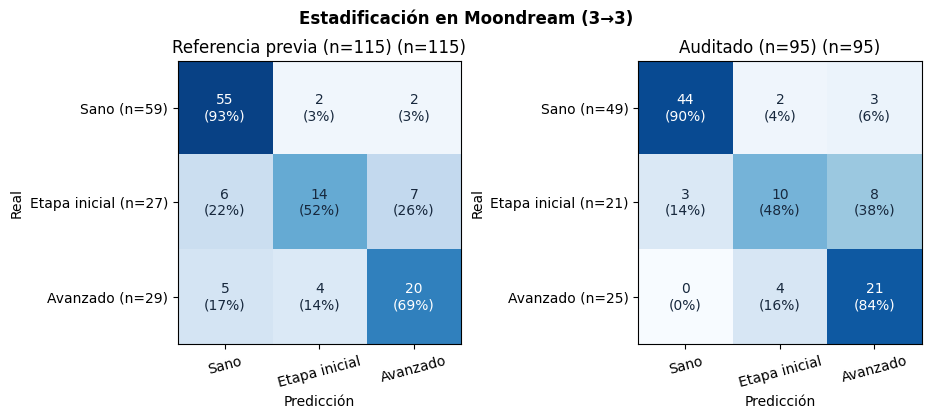

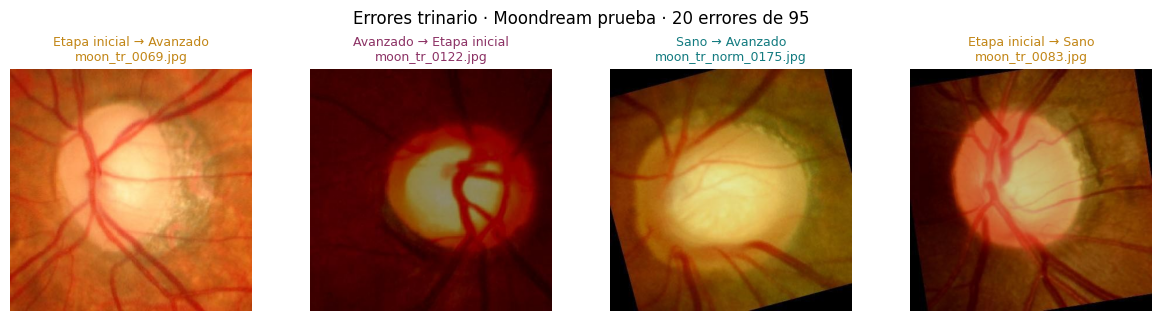

In [2]:
tf_eval = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(u.MEAN, u.STD)])
tf_train = T.Compose([
    T.RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.95, 1.05)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.03),
    T.ToTensor(),
    T.Normalize(u.MEAN, u.STD),
])

corridas = {}
for n_clases in (3, 2):
    ruta_pth = MODELOS / f"convnext_tiny_{n_clases}c_estandar.pth"
    res = u.entrenar_o_cargar(
        train_df, val_df, ROOT, n_clases, tf_train, tf_eval,
        ruta_modelo=ruta_pth, epochs=EPOCHS, batch_size=BATCH_SIZE,
        device=DEVICE, reentrenar=REENTRENAR, cache_imgs=cache_imgs,
    )
    y_val = val_df[f"y{n_clases}"].to_numpy(int)
    y_val_bin = val_df["y2"].to_numpy(int)
    tau, espec = u.calibrar_umbral(y_val, res["val_prob"], n_clases)
    tau_bin, espec_bin = (u.calibrar_umbral(y_val_bin, res["val_prob"], 2) if n_clases == 3 else (tau, espec))
    tau_youd, espec_youd = u.calibrar_youden(y_val_bin, res["val_prob"])

    probs = {}
    for nombre, df_eval in eval_sets.items():
        nivel = n_clases if nombre == "Moondream · test" else 2
        loader = u.crear_loader(df_eval, ROOT, nivel, tf_eval, batch_size=BATCH_SIZE, device=DEVICE, cache_imgs=cache_imgs)
        _, probs[nombre] = u.predecir(res["model"], loader, DEVICE, calcular_loss=False)

    corridas[n_clases] = {
        "hist": res["hist"], "epoca": res["epoca"], "tau": tau, "espec": espec,
        "tau_bin": tau_bin, "espec_bin": espec_bin,
        "tau_youd": tau_youd, "espec_youd": espec_youd, "probs": probs,
    }
    print(f"Modelo {n_clases} clases · mejor ép. {res['epoca']} · τ(Espec≥0.95)={tau_bin:.2f} (val={espec_bin:.3f}) · τ(Youden)={tau_youd:.2f} (val={espec_youd:.3f})")
    del res["model"]
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

# 1) Curvas de entrenamiento y validación (épocas 1..20)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True, layout="constrained")
for ax, n_cl, tit in zip(axes, (3, 2), ("Trinario (3 clases)", "Binario directo (2 clases)")):
    h = corridas[n_cl]["hist"]
    ep_best = corridas[n_cl]["epoca"]
    ax.plot(h["epoca"], h["train"], "o-", color="#2b6cb0", ms=3, label="Entrenamiento")
    ax.plot(h["epoca"], h["val"], "s-", color="#d97706", ms=3, label="Validación")
    ax.axvline(ep_best, ls="--", color="#111111", lw=1.1, label=f"Mejor época ({ep_best})")
    ax.set(title=tit, xlabel="Época", ylabel="Pérdida (entropía cruzada)")
    ax.grid(True, ls=":", alpha=0.45)
    ax.legend(fontsize=8)
fig.suptitle("Convergencia en Moondream · sobreajuste temprano del binario (ép. 3) vs. trinario (ép. 10)", fontweight="bold")
plt.show()

# 2) Comparación 3x3: referencia previa (n=115) vs. prueba auditada (n=95)
MATRIZ_REF = np.array([[55, 2, 2], [6, 14, 7], [5, 4, 20]])
y_ref, pred_ref = np.repeat(np.indices((3, 3)).reshape(2, -1), MATRIZ_REF.ravel(), axis=1)
metricas_ref, _ = u.calcular_metricas(y_ref, pred_ref, 3)

df_test_moon = eval_sets["Moondream · test"]
y3_test = df_test_moon["y3"].to_numpy(int)
pred3_test = u.decidir_con_umbral(corridas[3]["probs"]["Moondream · test"], corridas[3]["tau"])
met3, cm3 = u.calcular_metricas(y3_test, pred3_test, 3)

display(pd.DataFrame(
    [metricas_ref, met3],
    index=["Referencia previa (n=115, ép. 8)", "ConvNeXt 3c auditado (n=95, ép. 10)"],
).round(3))
u.graficar_matrices({"Referencia previa (n=115)": MATRIZ_REF, "Auditado (n=95)": cm3}, u.CLASES_3, "Estadificación en Moondream (3→3)")
u.mostrar_errores(df_test_moon, y3_test, pred3_test, u.CLASES_3, ROOT, "Errores trinario · Moondream prueba")

## 3. Detección binaria fuera de dominio y sensibilidad al umbral (`3→2` vs. `2→2`)

Proyectamos las probabilidades del modelo trinario mediante `P(pos) = P(Inicial) + P(Avanzado)` y comparamos frente al clasificador binario directo tanto en prueba interna (`Moondream`) como en las tres cohortes externas ciegas (`ACRIMA`, `RIM-ONE DL`, `EyePACS REAL`), evaluando además `Youden (val)` y `τ = 0.50` junto a `Espec. val ≥ 0.95`.

,cohorte,modelo,tau,n,F1 macro,sensibilidad,especificidad,TFN,AUROC
0,Moondream · test,Proyección trinario,0.81,95,0.916,0.935,0.898,0.065,0.980
1,Moondream · test,Entrenado binario,0.90,95,0.852,0.804,0.898,0.196,0.954
2,ACRIMA,Proyección trinario,0.81,703,0.671,0.775,0.565,0.225,0.740
3,ACRIMA,Entrenado binario,0.90,703,0.598,0.699,0.497,0.301,0.626
4,RIM-ONE DL,Proyección trinario,0.81,447,0.735,0.691,0.786,0.309,0.815
5,RIM-ONE DL,Entrenado binario,0.90,447,0.682,0.673,0.709,0.327,0.780
6,EyePACS REAL,Proyección trinario,0.81,200,0.353,0.020,0.990,0.980,0.552
7,EyePACS REAL,Entrenado binario,0.90,200,0.333,0.000,1.000,1.000,0.628


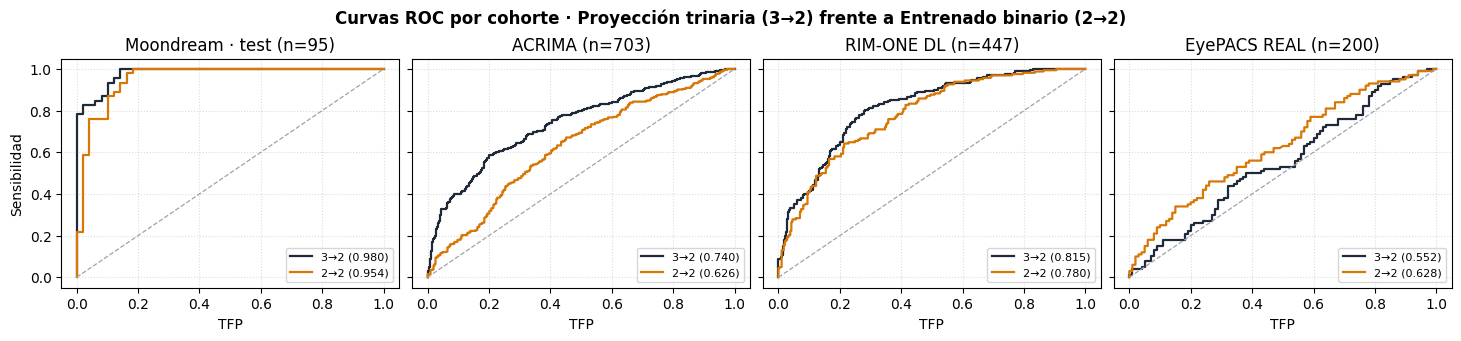

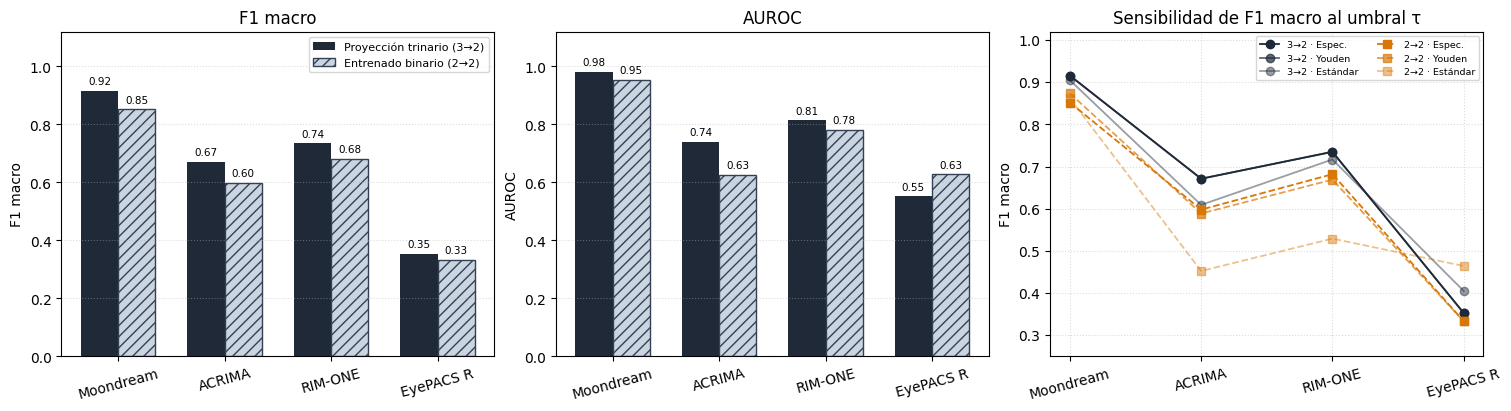

Diferencia pareada (Entrenado binario − Proyección trinario) con IC 95% bootstrap (2.000 réplicas):


,medida,delta,ic95_inf,ic95_sup,cohorte,n
0,F1 macro,-0.064,-0.141,0.010,Moondream · test,95
1,sensibilidad,-0.130,-0.240,-0.022,Moondream · test,95
3,AUROC,-0.026,-0.063,0.002,Moondream · test,95
4,F1 macro,-0.073,-0.102,-0.043,ACRIMA,703
5,sensibilidad,-0.076,-0.114,-0.041,ACRIMA,703
7,AUROC,-0.114,-0.141,-0.090,ACRIMA,703
8,F1 macro,-0.053,-0.093,-0.016,RIM-ONE DL,447
9,sensibilidad,-0.019,-0.086,0.049,RIM-ONE DL,447
11,AUROC,-0.034,-0.064,-0.007,RIM-ONE DL,447
12,F1 macro,-0.019,-0.052,0.004,EyePACS REAL,200


In [3]:
registros, intervalos, predicciones_out, sens_umbral = [], [], [], []
scores_por_cohorte = {}

for fuente, df_eval in eval_sets.items():
    y2 = df_eval["y2"].to_numpy(int)
    scores, decisiones = {}, {}

    for n_clases, etiqueta in ((3, "Proyección trinario"), (2, "Entrenado binario")):
        prob = corridas[n_clases]["probs"][fuente]
        sc = u.p_positivo(prob)
        tau_cons = corridas[n_clases]["tau_bin"]
        pred = (sc >= tau_cons).astype(int)
        scores[etiqueta] = sc
        decisiones[etiqueta] = pred
        stats, _ = u.calcular_metricas(y2, pred, 2, score_binario=sc)
        registros.append({"cohorte": fuente, "modelo": etiqueta, "tau": tau_cons, **stats})
        predicciones_out.append(df_eval[["id", "clase", "grupo", "y2"]].assign(
            cohorte=fuente, modelo=etiqueta, pred=pred, prob=sc
        ))
        for regla, t_val in [
            ("Espec. val ≥ 0.95", tau_cons),
            ("Youden (val)", corridas[n_clases]["tau_youd"]),
            ("Estándar (τ = 0.50)", 0.50),
        ]:
            m_t, _ = u.calcular_metricas(y2, (sc >= t_val).astype(int), 2, score_binario=sc)
            sens_umbral.append({"cohorte": fuente, "modelo": etiqueta, "regla": regla, "tau": t_val, **m_t})

    scores_por_cohorte[fuente] = (y2, scores)
    ic = u.bootstrap_diferencia(
        y2, decisiones["Proyección trinario"], decisiones["Entrenado binario"], 2,
        score_antes=scores["Proyección trinario"], score_despues=scores["Entrenado binario"],
    )
    if len(ic):
        intervalos.append(ic.assign(cohorte=fuente, n=len(df_eval)))

resumen_bin = pd.DataFrame(registros)
resumen_sens = pd.DataFrame(sens_umbral)
resumen_bin.to_csv(SALIDAS / "01_metricas_binarias.csv", index=False)
resumen_sens.to_csv(SALIDAS / "01_sensibilidad_umbral.csv", index=False)
pd.concat(predicciones_out, ignore_index=True).to_csv(SALIDAS / "01_predicciones_binarias.csv", index=False)

display(resumen_bin[["cohorte", "modelo", "tau", "n", "F1 macro", "sensibilidad", "especificidad", "TFN", "AUROC"]].round(3))

# 1) Grilla 1x4 de curvas ROC comparativas (sin repetir 8 gráficos separados)
fig, axes = plt.subplots(1, 4, figsize=(14.5, 3.3), sharey=True, layout="constrained")
for ax, (fuente, (y2, sc_dict)) in zip(axes, scores_por_cohorte.items()):
    for col, (nom, sc) in zip(("#1f2937", "#d97706"), sc_dict.items()):
        fpr, tpr, _ = roc_curve(y2, sc)
        auc = roc_auc_score(y2, sc)
        ax.plot(fpr, tpr, color=col, lw=1.6, label=f"{nom.replace('Proyección trinario', '3→2').replace('Entrenado binario', '2→2')} ({auc:.3f})")
    ax.plot([0, 1], [0, 1], "--", color="#9ca3af", lw=0.9)
    ax.set(title=f"{fuente} (n={len(y2)})", xlabel="TFP")
    ax.grid(True, ls=":", alpha=0.45)
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("Sensibilidad")
fig.suptitle("Curvas ROC por cohorte · Proyección trinaria (3→2) frente a Entrenado binario (2→2)", fontweight="bold")
plt.show()

# 2) Resumen F1 macro y AUROC + sensibilidad al punto de corte
cohortes_ord = ["Moondream · test", "ACRIMA", "RIM-ONE DL", "EyePACS REAL"]
proy = resumen_bin[resumen_bin["modelo"] == "Proyección trinario"].set_index("cohorte").loc[cohortes_ord]
bin_ = resumen_bin[resumen_bin["modelo"] == "Entrenado binario"].set_index("cohorte").loc[cohortes_ord]
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15.0, 4.0), layout="constrained")
x = np.arange(len(cohortes_ord))
w = 0.35
for ax, met in zip((ax1, ax2), ("F1 macro", "AUROC")):
    b1 = ax.bar(x - w/2, proy[met], w, color="#1f2937", label="Proyección trinario (3→2)")
    b2 = ax.bar(x + w/2, bin_[met], w, color="#cbd5e1", edgecolor="#334155", hatch="///", label="Entrenado binario (2→2)")
    for b in list(b1) + list(b2):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=7.5)
    ax.set(title=met, ylim=(0, 1.12), ylabel=met)
    ax.set_xticks(x, ["Moondream", "ACRIMA", "RIM-ONE", "EyePACS R"], rotation=15)
    ax.grid(axis="y", ls=":", alpha=0.45)
ax1.legend(fontsize=8)

for mod, sty, col in [("Proyección trinario", "o-", "#1f2937"), ("Entrenado binario", "s--", "#d97706")]:
    for reg, alpha in [("Espec. val ≥ 0.95", 1.0), ("Youden (val)", 0.7), ("Estándar (τ = 0.50)", 0.45)]:
        vals = resumen_sens[(resumen_sens["modelo"] == mod) & (resumen_sens["regla"] == reg)].set_index("cohorte").loc[cohortes_ord, "F1 macro"].to_numpy()
        ax3.plot(x, vals, sty, color=col, alpha=alpha, lw=1.3, label=f"{'3→2' if 'Proy' in mod else '2→2'} · {reg.split()[0]}")
ax3.set(title="Sensibilidad de F1 macro al umbral τ", ylim=(0.25, 1.02), ylabel="F1 macro")
ax3.set_xticks(x, ["Moondream", "ACRIMA", "RIM-ONE", "EyePACS R"], rotation=15)
ax3.grid(True, ls=":", alpha=0.45)
ax3.legend(fontsize=6.8, ncol=2)
plt.show()

if intervalos:
    df_ic = pd.concat(intervalos, ignore_index=True)
    print("Diferencia pareada (Entrenado binario − Proyección trinario) con IC 95% bootstrap (2.000 réplicas):")
    display(df_ic[df_ic["medida"].isin(["F1 macro", "AUROC", "sensibilidad"])].round(3))

## 4. Conclusión, limitaciones y trabajo futuro

- **Conclusión principal:** entrenar con tres estadios en `Moondream` (`3→2`) actúa como regularizador frente al binario directo (`ép. 10` vs. `ép. 3`) y mejora significativamente la separación y el `F1` en recortes papilares cercanos (`Moondream`, `ACRIMA +11,4 pp AUROC`, `RIM-ONE DL +3,4 pp AUROC`), manteniéndose bajo las tres reglas de umbral. Sin embargo, al provenir de un único dominio sin diversidad de campo amplio, **ambos colapsan sobre `EyePACS REAL`** (sensibilidad `≤ 15 %`, e incluso con `AUROC` inferior en el trinario: `0,552` frente a `0,628`).
- **Limitante y trabajo futuro:** el principal cuello de botella para escalar el análisis por severidad es la escasez de conjuntos públicos multicéntricos con etiquetas clínicas confiables y verificadas por estadio (frente a las cohortes binarias auditadas), además del desbalance `2:1:1` y la semilla única (`42`). Como trabajo futuro queda incorporar nuevas bases estadificadas de distintas cámaras y centros; entretanto, el experimento `05` abandona la restricción trinaria de origen único para evaluar un protocolo **LODO binario multi-semilla** con aumento de escala e iluminación.